# Portfolio stress and hedging

Research question: Does matching parallel duration eliminate nonparallel risk?

Inputs: frozen Treasury 2024–2025 CSVs. Rates are decimals, prices per 100 face. Release 1.0.0. No live signal.

In [1]:
import sys,json
from pathlib import Path
from datetime import date
import numpy as np
R=Path.cwd()
if R.name=='notebooks':R=R.parent
sys.path.insert(0,str(R/'src'));sys.path.insert(0,str(R/'scripts'))
from curve_lab.data import load_history
from curve_lab.bonds import Bond
from curve_lab.curves import bootstrap,par_rate,TENORS,KEYS,fit_nelson_siegel
from curve_lab.risk import bond_risk,hedge,carry_bridge
from curve_lab.forecast import predict,evaluate
from review_display import table,figure
if 'display_bundle' not in globals():
    from IPython.display import display
    def display_bundle(bundle):display(bundle,raw=True)
D=json.loads((R/'artifacts/release/research.json').read_text());rows,receipts=load_history(R)
print('Run',D['run_id'],'| source through',D['as_of'],'| hypothetical bond valuations')


Run p4-662f58a64e8e | source through 2025-12-31 | hypothetical bond valuations


## Read equal-capital portfolio exposures

In [2]:
display_bundle(table(['Portfolio','Capital','Duration','DV01'],[[n,p['capital'],p['duration'],p['dv01']] for n,p in D['portfolios'].items()]));assert abs(D['portfolios']['Bullet']['duration']-D['portfolios']['Barbell']['duration'])<1e-10

Portfolio,Capital,Duration,DV01
Bullet,1000000,4.5849337,458.49337
Barbell,1000000,4.5849337,458.49337
Ladder,1000000,2.823403,282.3403


## Independently resolve the bounded hedge

Key,Before,After
0.5,3.1788857,2.6718507
2,20.105869,-0.044549906
5,434.97915,430.72342
10,0.22946613,-42.70479
20,0,-0.021825626
30,0,0


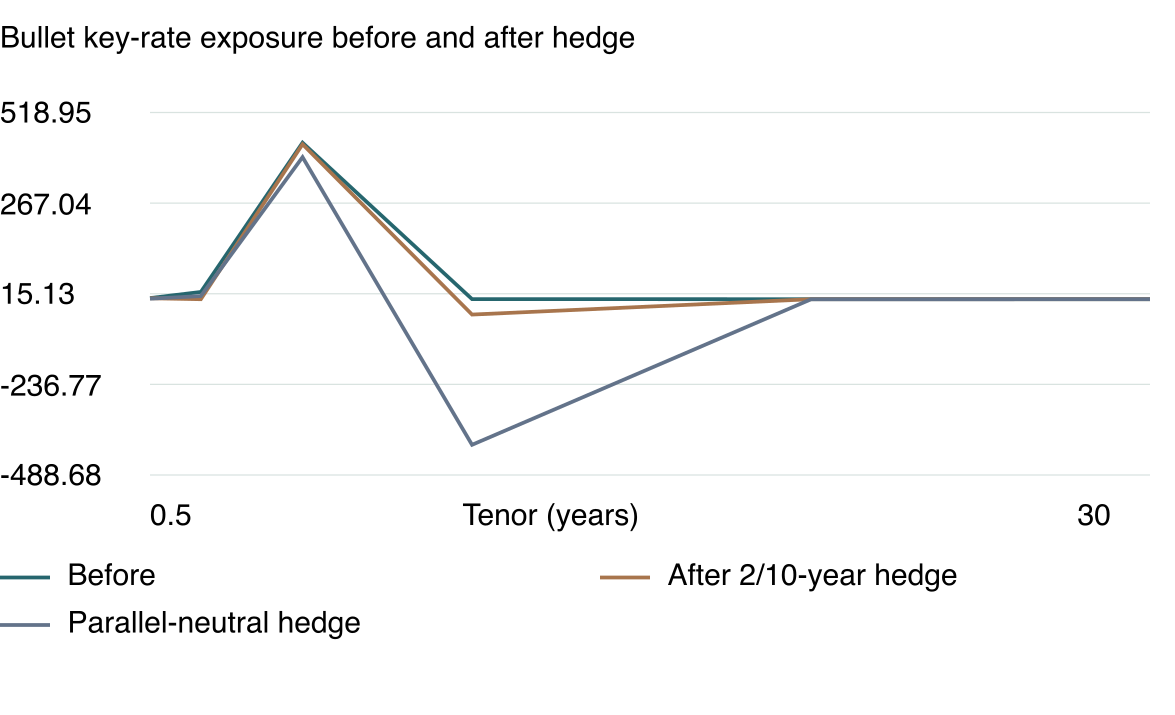

In [3]:
h=hedge(D['hedge']['before'],np.array(D['hedge_review_inputs']).T);display_bundle(table(['Key','Before','After'],zip(KEYS,h['before'],h['after'])));assert np.max(abs(np.array(h['units'])-D['hedge']['units']))<1e-7;assert h['after_norm']<h['before_norm'];display_bundle(figure('hedge'))

## Challenge full repricing after the hedge

In [4]:
display_bundle(table(['Scenario','Bullet','Barbell','Hedged bullet'],[[s,D['portfolios']['Bullet']['stress'][s],D['portfolios']['Barbell']['stress'][s],D['hedge']['stress_after'][s]] for s in D['shocks']]));print('Hedge one-way cost USD',D['hedge']['one_way_cost_usd'])

Scenario,Bullet,Barbell,Hedged bullet
Parallel +100,-44757.814,-44179.212,-38209.442
Parallel -100,46977.252,47624.61,39936.91
Parallel +200,-87402.726,-85213.805,-74755.44
Steepener,1157.5602,-8681.268,2217.3
Flattener,-1147.9969,9480.5416,-2321.9813
Butterfly,-20914.686,-13254.924,-19128.384
2025 curve change replay,29726.656,22221.474,26343.95


Hedge one-way cost USD 31.538590241836996


## Interpretation

Two hedge instruments cannot span six independent buckets. The saved solution reduces an explicit L2 objective and leaves residual twist risk. Instantaneous stress P&L excludes overlay costs and future financing.

Canonical evidence: `artifacts/release/research.json`; source receipts: `data/manifests/sources.json`.